# Fitting a sine wave with an eddy-like background

This experiment examines how the number of observations affects a fitted wave amplitude when the observations contain independent noise and a smooth spatial background. 


## 1. Data and fit

Add independent observation noise and a smooth background to a known sine wave:

$$y(x)=A\cos(kx-\phi)+m(x)+\epsilon(x),\qquad
m(x)=h\exp\left[-\frac{(x-x_0)^2}{2w^2}\right].$$

The window is 120 km long and the wavelength is 60 km, so the window contains two complete wave cycles. The true amplitude is 0.5 cm, the phase is 40 degrees, and the observation-noise standard deviation is 0.16 cm. Noise is independent between points and trials at every point spacing used here.

For each trial, draw the background height from a normal distribution with mean 0 and standard deviation 1 cm, and its center uniformly from -60 to 60 km. These two draws are independent. The Gaussian width is fixed at 60 km; it describes the shape of each background curve.

Fit only $a\cos(kx)+b\sin(kx)$ at the known wavenumber $k=2\pi/\lambda$, and calculate the amplitude as $\sqrt{a^2+b^2}$. No constant or background term is included in the fit. In the code below, distances are in km and SSH values are in cm.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

window = 120.0
wavelength = 60.0
true_amplitude = 0.5
phase = np.deg2rad(40.0)
noise_sd = 0.16
eddy_height_sd = 1.0
eddy_width = 60.0
sample_counts = [8, 16, 32, 64]
n_trials = 2000
seed = 24

plt.rcParams.update({"font.size": 11, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})

def wave_grid(n, wave_length):
    x = -window / 2 + (np.arange(n) + 0.5) * window / n
    H = np.column_stack([np.cos(2 * np.pi * x / wave_length),
                         np.sin(2 * np.pi * x / wave_length)])
    wave = true_amplitude * np.cos(2 * np.pi * x / wave_length - phase)
    return x, H, wave

def fit_amplitude(H, y):
    coefficients = np.linalg.lstsq(H, y, rcond=None)[0]
    return np.hypot(coefficients[0], coefficients[1])

rng = np.random.default_rng(seed)
heights = rng.normal(0, eddy_height_sd, n_trials)
centers = rng.uniform(-window / 2, window / 2, n_trials)


## 2. Compare fits with and without the background

The observation window stays fixed at 120 km. Points are placed at the centers of equal-width intervals, with spacing 120/N km:

| Number of points | Point spacing (km) |
|---:|---:|
| 8 | 15 |
| 16 | 7.5 |
| 32 | 3.75 |
| 64 | 1.875 |

For each number of observation points, compare two cases:

- **No background:** the sine wave + observation noise.
- **Eddy-like background:** the same sine wave + the same noise + an eddy-like background.

Fit only the sine and cosine terms in both cases. Run 2,000 trials for each point count, keeping the true wave fixed. The same 2,000 background curves are sampled at each point count. A separate noise array is generated for each point count and shared between the two cases.

**SD** is the sample standard deviation of fitted amplitudes across trials (using N_trials - 1 in the denominator). **Bias** is the average fitted amplitude minus the true amplitude. **RMSE** is the root-mean-square error relative to the true amplitude. All three are in cm.

In [2]:
rows = []
for n in sample_counts:
    x, H, wave = wave_grid(n, wavelength)
    noise = np.random.default_rng(seed + n).normal(0, noise_sd, (n, n_trials))
    background = heights[None, :] * np.exp(
        -0.5 * ((x[:, None] - centers[None, :]) / eddy_width)**2)
    base = wave[:, None] + noise
    np.testing.assert_allclose(fit_amplitude(H, wave), true_amplitude, atol=1e-12)

    for case, y in [("No background", base), ("Eddy-like background", base + background)]:
        amplitude = fit_amplitude(H, y)
        error = amplitude - true_amplitude
        rows.append({"N": n, "Data": case, "Bias (cm)": error.mean(),
                     "SD (cm)": amplitude.std(ddof=1),
                     "RMSE (cm)": np.sqrt(np.mean(error**2))})

results = pd.DataFrame(rows)
print(f"{n_trials:,} repeats for each number of points; wavelength = {wavelength:g} km")
print(results.round(4).to_string(index=False))


2,000 repeats for each number of points; wavelength = 60 km
 N                 Data  Bias (cm)  SD (cm)  RMSE (cm)
 8        No background     0.0074   0.0813     0.0816
 8 Eddy-like background     0.0112   0.1040     0.1045
16        No background     0.0039   0.0559     0.0560
16 Eddy-like background     0.0067   0.0834     0.0836
32        No background    -0.0005   0.0399     0.0399
32 Eddy-like background     0.0022   0.0720     0.0720
64        No background     0.0003   0.0293     0.0293
64 Eddy-like background     0.0029   0.0663     0.0663


## 3. Example and results

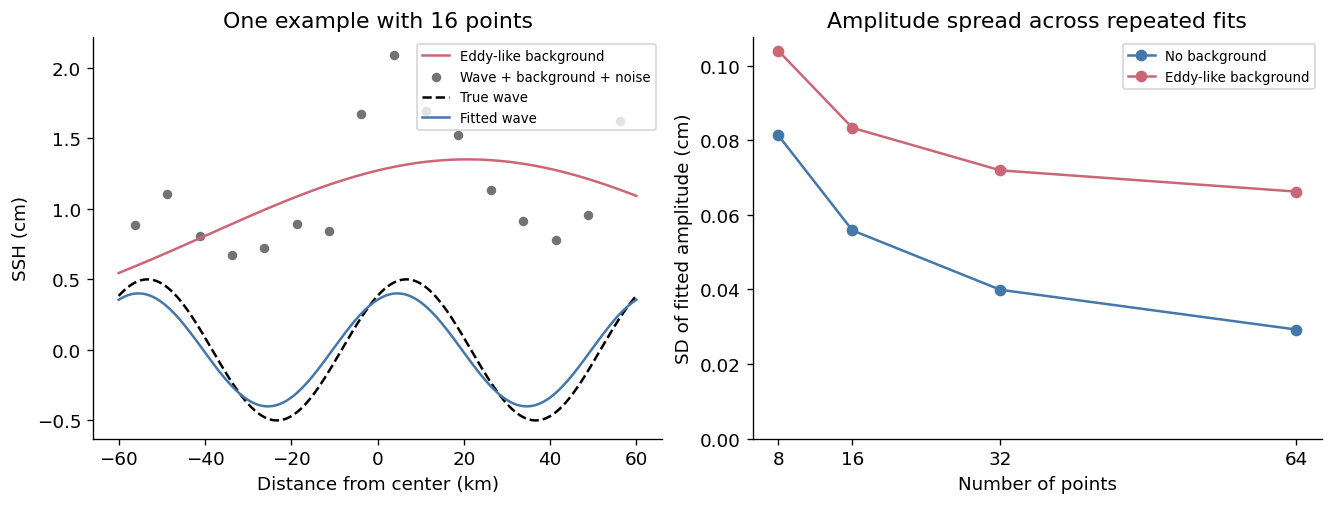

In [3]:
# Show one background curve and how the amplitude spread changes with point count.
n_example = 16
x, H, wave = wave_grid(n_example, wavelength)
noise = np.random.default_rng(seed + n_example).normal(0, noise_sd, (n_example, n_trials))
background = heights[0] * np.exp(-0.5 * ((x - centers[0]) / eddy_width)**2)
y = wave + background + noise[:, 0]
coefficients = np.linalg.lstsq(H, y, rcond=None)[0]
xd = np.linspace(-window / 2, window / 2, 500)
Hd = np.column_stack([np.cos(2 * np.pi * xd / wavelength),
                      np.sin(2 * np.pi * xd / wavelength)])
wave_dense = true_amplitude * np.cos(2 * np.pi * xd / wavelength - phase)
background_dense = heights[0] * np.exp(-0.5 * ((xd - centers[0]) / eddy_width)**2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), constrained_layout=True)
axes[0].plot(xd, background_dense, color="#CC6677", label="Eddy-like background")
axes[0].scatter(x, y, color="0.45", s=22, label="Wave + background + noise")
axes[0].plot(xd, wave_dense, "k--", label="True wave")
axes[0].plot(xd, Hd @ coefficients, color="#4477AA", label="Fitted wave")
axes[0].set(title="One example with 16 points", xlabel="Distance from center (km)",
            ylabel="SSH (cm)")
axes[0].legend(fontsize=8, loc="upper right")

for case, color in [("No background", "#4477AA"), ("Eddy-like background", "#CC6677")]:
    part = results[results["Data"] == case]
    axes[1].plot(part["N"], part["SD (cm)"], "o-", color=color, label=case)
axes[1].set(title="Amplitude spread across repeated fits", xlabel="Number of points",
            ylabel="SD of fitted amplitude (cm)")
axes[1].set_xticks(sample_counts)
axes[1].set_ylim(bottom=0)
axes[1].legend(fontsize=8)
plt.show()


The left panel shows the first trial with 16 observation points, spaced 7.5 km apart. The fitted wave is obtained from the wave + background + noise.

The right panel shows the SD of fitted amplitudes across 2,000 trials for each point count (8, 16, 32, and 64), with and without the eddy-like background.

With the eddy-like background, increasing the point count from 8 to 64 reduces the amplitude SD from 0.1040 to 0.0663 cm (0.104 to 0.066 cm when rounded to three decimals). The corresponding values without the background are 0.0813 and 0.0293 cm. Additional observations improve the amplitude estimate in this experiment, while the background still contributes to its variability.

In [4]:
import sys, matplotlib
print(f"Python {sys.version.split()[0]}; NumPy {np.__version__}; "
      f"pandas {pd.__version__}; Matplotlib {matplotlib.__version__}")

Python 3.13.12; NumPy 2.4.6; pandas 3.0.5; Matplotlib 3.10.9
